<a href="https://colab.research.google.com/github/atur0021/MMA3001-Project/blob/main/MMA3001-Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**INPUT PARAMETERS**

In [8]:
csv_name = 'MKII_Hotfire_02_05_2026_Thrust.csv' #file name of thrust data file to use
oxidiser_mass = 5.8 #kg
rocket_dry_mass = 25 #kg
rocket_diameter = 0.1524 #m
rocket_Cd = 0.38 #dimensionless
plot_meridian_flight_one = True #boolean

**READING IN DATA FROM GITHUB**

In [9]:
import pandas as pd
import requests
import io
import os
from google.colab import userdata

# Fetch token from Colab Secrets
try:
    token = userdata.get('GH_PAT')
except Exception:
    token = None

# List of all thrust CSV URLs
csv_urls = [
    'https://raw.githubusercontent.com/atur0021/MMA3001-Project/main/data/MKII_Hotfire_02_05_2026_Thrust.csv',
    'https://raw.githubusercontent.com/atur0021/MMA3001-Project/main/data/MKII_Hotfire_30_08_2026_Thrust.csv',
    'https://raw.githubusercontent.com/atur0021/MMA3001-Project/main/data/MKII_Hotfire_06_07_2024_Thrust.csv'
]

# Setup headers for private authentication if token is available
headers = {}
if token:
    headers['Authorization'] = f'token {token}'

# Initialising a dictionary to hold all loaded DataFrames
dfs = {}

for url in csv_urls:
    # Extract a friendly name from the URL to use as a dictionary key
    file_name = url.split('/')[-1]
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()

        # Load the CSV data and store it
        dfs[file_name] = pd.read_csv(io.StringIO(response.text))
        print(f"Successfully loaded: {file_name} ({len(dfs[file_name])} rows)")
    except Exception as e:
        print(f"Error loading {file_name}: {e}")

# Conditionally load the cleaned flight data
flight_df = None
if globals().get('plot_meridian_flight_one', False):
    flight_url = 'https://raw.githubusercontent.com/atur0021/MMA3001-Project/main/data/cleaned_flight_data.csv'
    try:
        response = requests.get(flight_url, headers=headers)
        response.raise_for_status()
        flight_df = pd.read_csv(io.StringIO(response.text))
        print(f"Successfully loaded flight data: cleaned_flight_data.csv ({len(flight_df)} rows)")
    except Exception as e:
        print(f"Error loading cleaned_flight_data.csv: {e}")

Successfully loaded: MKII_Hotfire_02_05_2026_Thrust.csv (45044 rows)
Successfully loaded: MKII_Hotfire_30_08_2026_Thrust.csv (7634 rows)
Successfully loaded: MKII_Hotfire_06_07_2024_Thrust.csv (115750 rows)
Successfully loaded flight data: cleaned_flight_data.csv (5136 rows)


**TRIMMING THRUST DATA TO REGION OF INTEREST**

--- Dynamic Propellant Mass Correction Complete for MKII_Hotfire_30_08_2026_Thrust.csv ---
Detected Ignition Time: 0.314 s
Pre-ignition Background Offset (Full Wet Mass): 342.80 N
Total weight shift from propellant consumption: 56.88 N
Trimmed data size: 7235 active rows.



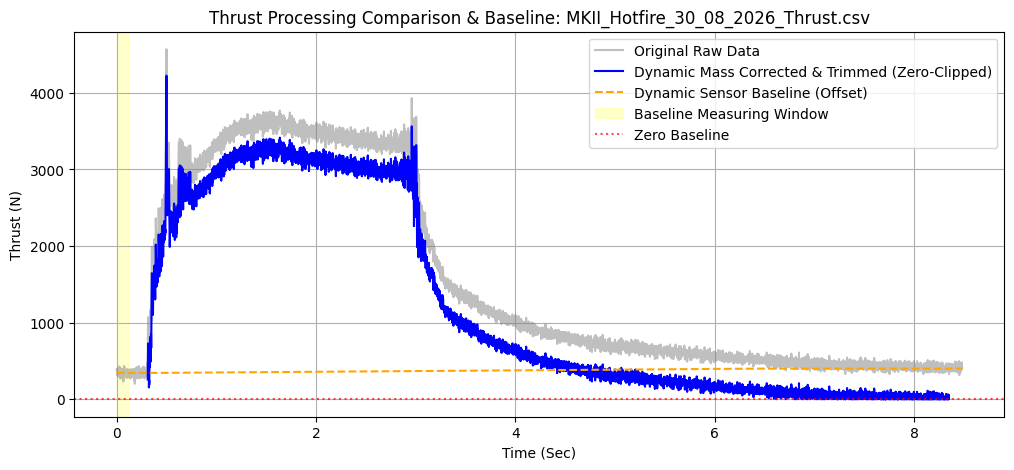

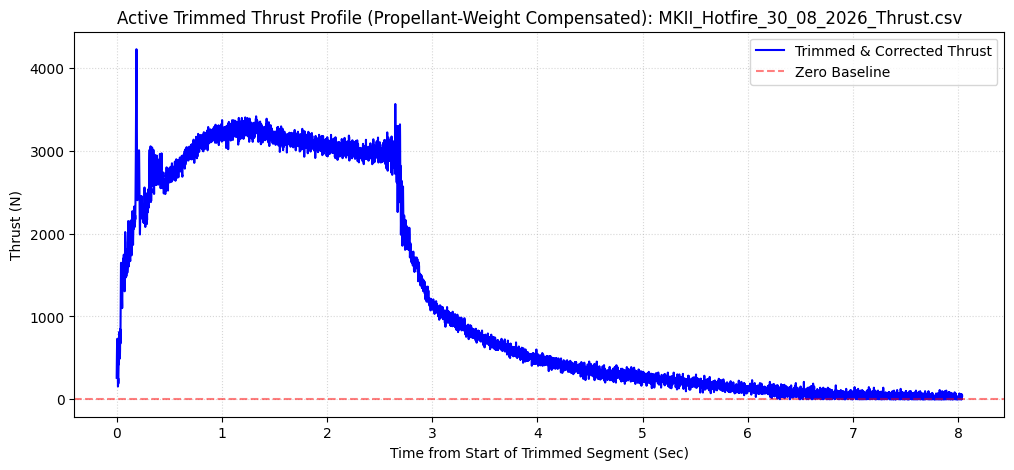

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def preprocess_and_trim_thrust_data(df, csv_name, oxidiser_mass, burn_duration=6.0):
    """Cleans, applies dynamic mass depletion offset correction, and trims thrust data.

    Args:
        df (pd.DataFrame): The raw thrust DataFrame containing time and thrust columns.
        csv_name (str): The filename of the dataset being processed.
        oxidiser_mass (float): Mass of the liquid oxidizer in kg.
        burn_duration (float, optional): Estimated motor burn time in seconds. Defaults to 6.0.

    Returns:
        pd.DataFrame: The trimmed, baseline-corrected, and time-shifted active thrust dataset.
    """
    # 1. Dynamically find column names
    time_col = [col for col in df.columns if 'time' in col.lower()][0]
    thrust_col = [col for col in df.columns if 'thrust' in col.lower()][0]

    # 2. Safely cast to numeric types
    df[time_col] = pd.to_numeric(df[time_col], errors='coerce')
    df[thrust_col] = pd.to_numeric(df[thrust_col], errors='coerce')
    df = df.dropna(subset=[time_col, thrust_col]).reset_index(drop=True)

    # 3. Find when thrust actually begins (approximate ignition point)
    early_noise_std = df[thrust_col].iloc[:50].std()
    early_noise_mean = df[thrust_col].iloc[:50].mean()

    ignition_threshold = early_noise_mean + (12 * early_noise_std)
    ignition_candidates = df[df[thrust_col] > ignition_threshold].index

    if len(ignition_candidates) == 0:
        raise ValueError("Could not automatically identify any ignition spike above noise threshold.")

    raw_ignition_idx = ignition_candidates[0]
    raw_ignition_time = df.loc[raw_ignition_idx, time_col]

    # 4. Calculate baseline from a 2-second window immediately preceding ignition
    time_step = df[time_col].diff().median()
    pts_per_sec = int(1.0 / time_step) if time_step > 0 else 100
    baseline_window_size = int(2.0 * pts_per_sec)

    start_baseline_idx = max(0, raw_ignition_idx - baseline_window_size)
    end_baseline_idx = max(0, raw_ignition_idx - int(0.2 * pts_per_sec))

    baseline_df = df.iloc[start_baseline_idx:end_baseline_idx]
    background_thrust_pre = baseline_df[thrust_col].mean()

    if pd.isna(background_thrust_pre):
        background_thrust_pre = early_noise_mean

    # 5. Apply linear mass depletion correction
    g = 9.80665

    def calculate_dynamic_offset(row):
        t = row[time_col]
        if t < raw_ignition_time:
            return background_thrust_pre
        elif t <= (raw_ignition_time + burn_duration):
            fraction_burnt = (t - raw_ignition_time) / burn_duration
            depleted_force = fraction_burnt * (oxidiser_mass * g)
            return background_thrust_pre + depleted_force
        else:
            return background_thrust_pre + (oxidiser_mass * g)

    # Apply the correction
    df['Dynamic_Offset'] = df.apply(calculate_dynamic_offset, axis=1)
    df['Thrust_Corrected'] = df[thrust_col] - df['Dynamic_Offset']

    # 6. Locate the full active region using corrected values
    max_corrected_thrust = df['Thrust_Corrected'].max()
    active_threshold = 0.05 * max_corrected_thrust
    active_indices = df[df['Thrust_Corrected'] > active_threshold].index

    start_idx = max(0, active_indices[0])
    end_idx = min(len(df) - 1, active_indices[-1] + int(2.0 * pts_per_sec))

    df_trimmed_dynamic = df.iloc[start_idx:end_idx].copy()
    df_trimmed_dynamic['Thrust_Corrected'] = df_trimmed_dynamic['Thrust_Corrected'].clip(lower=0.0)

    # Shift the time axis of the trimmed data to start exactly at t = 0
    start_time = df_trimmed_dynamic[time_col].min()
    df_trimmed_dynamic['Time_Shifted'] = df_trimmed_dynamic[time_col] - start_time

    print(f"--- Dynamic Propellant Mass Correction Complete for {csv_name} ---")
    print(f"Detected Ignition Time: {raw_ignition_time:.3f} s")
    print(f"Pre-ignition Background Offset (Full Wet Mass): {background_thrust_pre:.2f} N")
    print(f"Total weight shift from propellant consumption: {oxidiser_mass * g:.2f} N")
    print(f"Trimmed data size: {len(df_trimmed_dynamic)} active rows.\n")

    return df_trimmed_dynamic, df, start_baseline_idx, end_baseline_idx


def plot_thrust_comparison(df, df_trimmed, start_baseline_idx, end_baseline_idx, csv_name):
    """Generates processing and active thrust diagnostic plots.

    Args:
        df (pd.DataFrame): Full processed DataFrame with baseline and corrected thrust columns.
        df_trimmed (pd.DataFrame): Trimmed active region DataFrame starting at t = 0.
        start_baseline_idx (int): Start index for baseline measuring window highlight.
        end_baseline_idx (int): End index for baseline measuring window highlight.
        csv_name (str): Name of the CSV file being processed.
    """
    time_col = [col for col in df.columns if 'time' in col.lower()][0]
    thrust_col = [col for col in df.columns if 'thrust' in col.lower()][0]

    # Plot original raw data vs corrected baseline full window comparison
    plt.figure(figsize=(12, 5))
    plt.plot(df[time_col], df[thrust_col], label='Original Raw Data', color='gray', alpha=0.5)
    plt.plot(df_trimmed[time_col], df_trimmed['Thrust_Corrected'], label='Dynamic Mass Corrected & Trimmed (Zero-Clipped)', color='blue')
    plt.plot(df[time_col], df['Dynamic_Offset'], label='Dynamic Sensor Baseline (Offset)', color='orange', linestyle='--')
    plt.axvspan(df.loc[start_baseline_idx, time_col], df.loc[end_baseline_idx, time_col], color='yellow', alpha=0.2, label='Baseline Measuring Window')
    plt.axhline(0, color='red', linestyle=':', alpha=0.7, label='Zero Baseline')
    plt.xlabel('Time (Sec)')
    plt.ylabel('Thrust (N)')
    plt.title(f'Thrust Processing Comparison & Baseline: {csv_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Plot ONLY the new trimmed and corrected active dataset starting at t = 0
    plt.figure(figsize=(12, 5))
    plt.plot(df_trimmed['Time_Shifted'], df_trimmed['Thrust_Corrected'], label='Trimmed & Corrected Thrust', color='blue', linewidth=1.5)
    plt.axhline(0, color='red', linestyle='--', alpha=0.5, label='Zero Baseline')
    plt.xlabel('Time from Start of Trimmed Segment (Sec)')
    plt.ylabel('Thrust (N)')
    plt.title(f'Active Trimmed Thrust Profile (Propellant-Weight Compensated): {csv_name}')
    plt.legend()
    plt.grid(True, which='both', linestyle=':', alpha=0.5)
    plt.show()

# Execute functions on loaded configurations
if csv_name in dfs:
    active_df, full_processed_df, s_idx, e_idx = preprocess_and_trim_thrust_data(dfs[csv_name], csv_name, oxidiser_mass)
    plot_thrust_comparison(full_processed_df, active_df, s_idx, e_idx, csv_name)
else:
    print(f"Error: '{csv_name}' was not found in loaded datasets.")

**FITTING A REGRESSION MODEL**



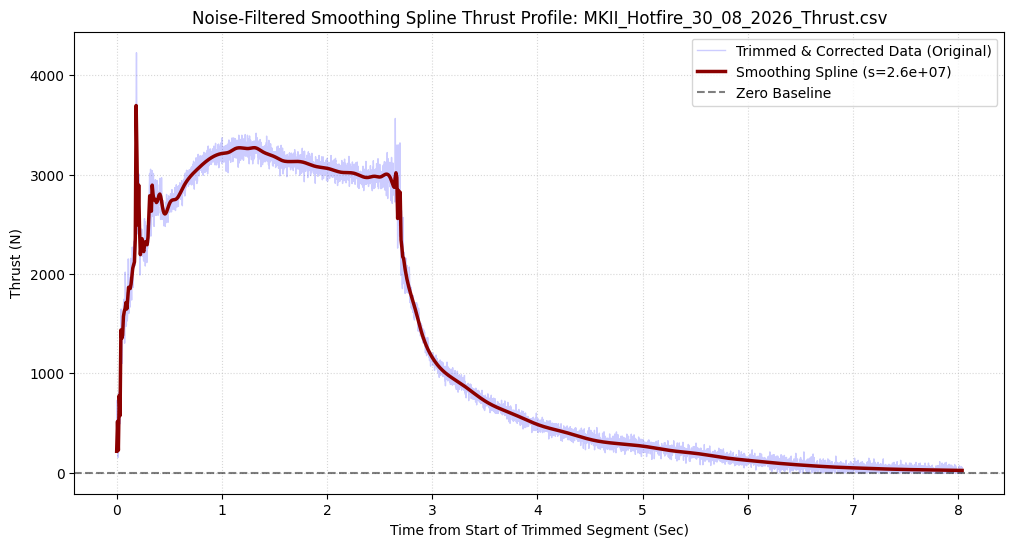

In [11]:
from scipy.interpolate import UnivariateSpline
import numpy as np
import matplotlib.pyplot as plt

def fit_smoothing_spline(active_df, smoothing_factor):
    """Fits a UnivariateSpline to the cleaned thrust data after resolving duplicate timestamps.

    Args:
        active_df (pd.DataFrame): Cleaned and shifted active thrust DataFrame.
        smoothing_factor (float): Smoothing parameter (s) for UnivariateSpline.

    Returns:
        tuple: (spline_object, x_smooth, y_smooth, x_unique, y_unique)
    """
    # Aggregate duplicate time values by their mean
    unique_data = active_df.groupby('Time_Shifted')['Thrust_Corrected'].mean().reset_index()
    x_unique = unique_data['Time_Shifted'].values
    y_unique = unique_data['Thrust_Corrected'].values

    # Fit UnivariateSpline
    spline = UnivariateSpline(x_unique, y_unique, s=smoothing_factor)

    # Generate evaluation grid
    x_smooth = np.linspace(x_unique.min(), x_unique.max(), 1000)
    y_smooth = spline(x_smooth)

    return spline, x_smooth, y_smooth, x_unique, y_unique


def plot_spline_fit(x_orig, y_orig, x_smooth, y_smooth, smoothing_factor, csv_name):
    """Plots original data points against fitted smoothing spline.

    Args:
        x_orig (np.ndarray): Original active segment shifted times.
        y_orig (np.ndarray): Original baseline corrected thrust values.
        x_smooth (np.ndarray): Uniformly sampled spline evaluation times.
        y_smooth (np.ndarray): Spline-predicted thrust values.
        smoothing_factor (float): The spline's smoothing factor.
        csv_name (str): Filename of the thrust profile.
    """
    plt.figure(figsize=(12, 6))
    plt.plot(x_orig, y_orig, label='Trimmed & Corrected Data (Original)', color='blue', alpha=0.2, linewidth=1)
    plt.plot(x_smooth, y_smooth, label=f'Smoothing Spline (s={smoothing_factor:.1e})', color='darkred', linewidth=2.5)
    plt.axhline(0, color='black', linestyle='--', alpha=0.5, label='Zero Baseline')
    plt.xlabel('Time from Start of Trimmed Segment (Sec)')
    plt.ylabel('Thrust (N)')
    plt.title(f'Noise-Filtered Smoothing Spline Thrust Profile: {csv_name}')
    plt.legend()
    plt.grid(True, which='both', linestyle=':', alpha=0.5)
    plt.show()

# Run fitting and visualization
if 'active_df' in globals() and active_df is not None:
    smoothing_factor = 2.6e7
    spline, smoothed_time, smoothed_thrust, x_unique, y_unique = fit_smoothing_spline(active_df, smoothing_factor)
    plot_spline_fit(active_df['Time_Shifted'].values, active_df['Thrust_Corrected'].values,
                    smoothed_time, smoothed_thrust, smoothing_factor, csv_name)
else:
    print("Error: 'active_df' is not defined. Please run the trimming cell first.")

In [12]:
def evaluate_spline_quality(spline, x_eval, y_true, smoothing_factor):
    """Calculates quality metrics (R-squared) for the fitted spline.

    Args:
        spline (UnivariateSpline): The fitted spline model object.
        x_eval (np.ndarray): Timestamps at which to evaluate spline predictions.
        y_true (np.ndarray): Ground truth thrust values at evaluation timestamps.
        smoothing_factor (float): Smoothing parameter (s) utilized during fitting.
    """
    y_pred = spline(x_eval)
    mean_y = np.mean(y_true)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - mean_y) ** 2)
    r_squared = 1 - (ss_res / ss_tot)

    print("--- Spline Fit Quality Metrics ---")
    print(f"Smoothing Factor (s): {smoothing_factor:.1e}")
    print(f"R-squared (R²): {r_squared:.6f}")

if 'spline' in globals() and 'x_unique' in globals() and 'y_unique' in globals():
    evaluate_spline_quality(spline, x_unique, y_unique, smoothing_factor)
else:
    print("Error: Spline model or data points not found in workspace.")

--- Spline Fit Quality Metrics ---
Smoothing Factor (s): 2.6e+07
R-squared (R²): 0.997828


**INTEGRATING SMOOTHED DATA FOR IMPULSE**

In [13]:
from scipy.integrate import simpson

def calculate_total_impulse(time, thrust):
    """Calculates total impulse using Simpson's integration rule.

    Args:
        time (np.ndarray): Array of timestamps.
        thrust (np.ndarray): Array of corresponding thrust values.

    Returns:
        float: Integrated total impulse (Ns).
    """
    total_impulse = simpson(y=thrust, x=time)
    print("--- Total Impulse Calculation ---")
    print(f"Total Impulse: {total_impulse:.1f} Ns")
    return total_impulse

if 'smoothed_time' in globals() and 'smoothed_thrust' in globals():
    total_impulse = calculate_total_impulse(smoothed_time, smoothed_thrust)
else:
    print("Error: Smoothed data variables not found.")

--- Total Impulse Calculation ---
Total Impulse: 9797.9 Ns


**SIMULATING FLIGHT**

--- RK4 Flight Simulation Complete (Continuous Spline Mode) ---
Apogee Altitude: 3273.3 m (10739.6 ft) at 25.95 s
Max Velocity: 254.0 m/s at 3.90 s


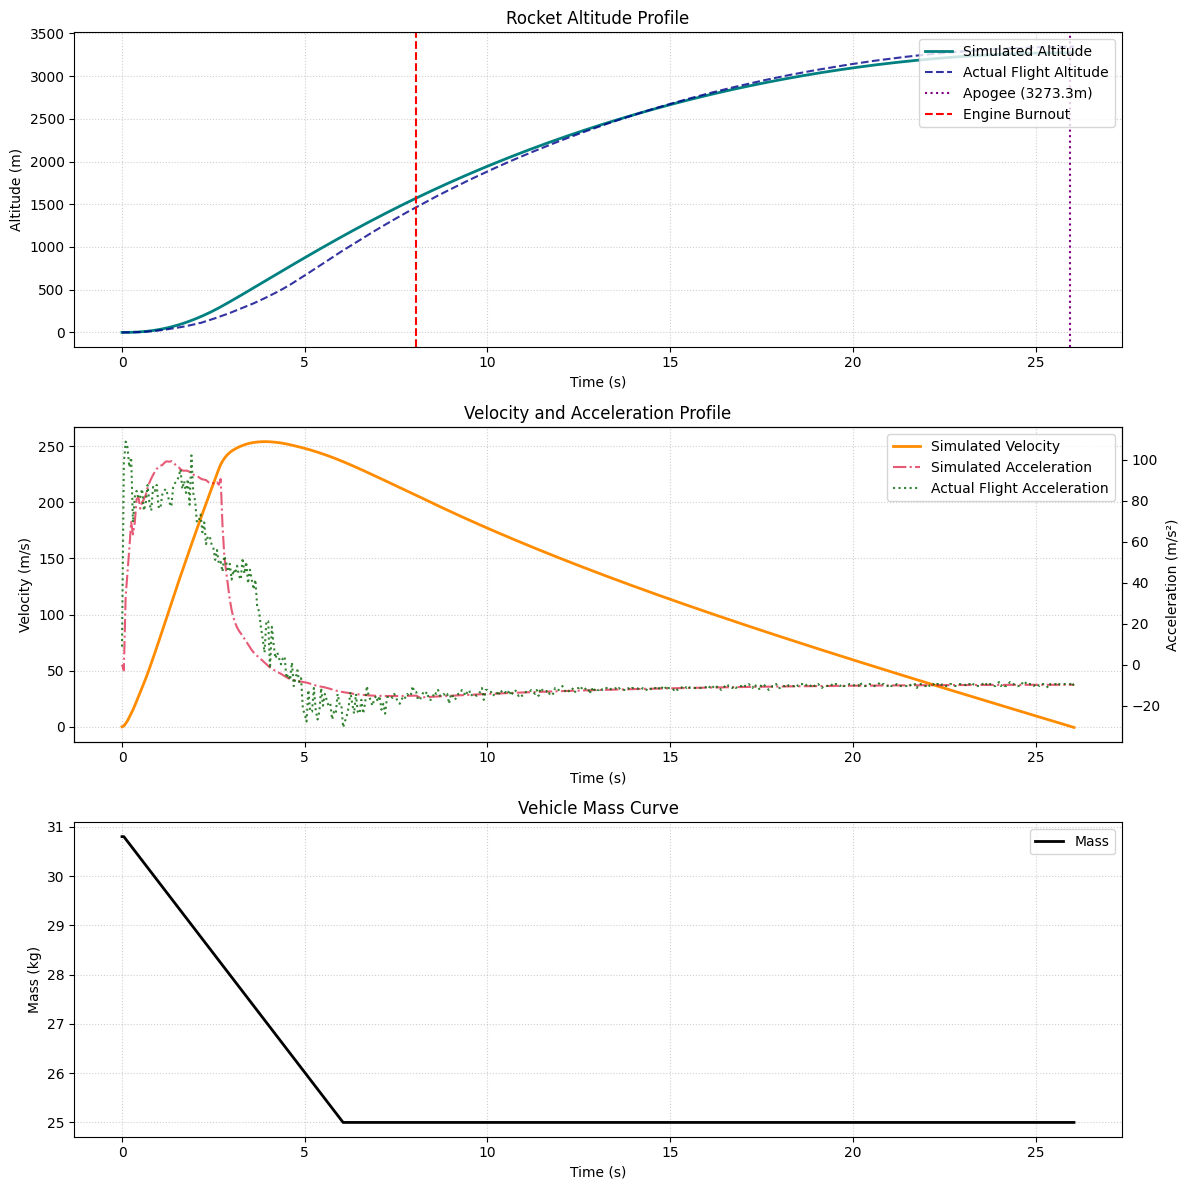

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def get_air_density(altitude):
    """Standard US Standard Atmosphere model approximation for air density with height.

    Args:
        altitude (float): Current altitude above sea level in meters.

    Returns:
        float: Atmospheric density in kg/m^3.
    """
    T0 = 288.15 # K
    L = 0.0065 # K/m (lapse rate)
    R = 287.05 # J/(kg*K)
    g = 9.80665 # m/s^2
    rho0 = 1.225 # kg/m^3

    if altitude < 0:
        return rho0
    elif altitude < 11000:
        T = T0 - L * altitude
        return rho0 * (T / T0) ** ((g / (L * R)) - 1)
    elif altitude < 20000:
        T = 216.65
        rho_11 = 0.36391
        return rho_11 * np.exp(-g * (altitude - 11000) / (R * T))
    else:
        return 0.0


def run_flight_simulation(spline, max_burn_time, vehicle_params, dt_burn=0.05, dt_coast=0.1):
    """Simulates 1D rocket trajectory utilizing an RK4 numerical solver.

    Args:
        spline (UnivariateSpline): Fitted continuous motor thrust model.
        max_burn_time (float): End of the active thrust timeline in seconds.
        vehicle_params (dict): Physics settings: m_dry, m_ox, diameter, Cd.
        dt_burn (float, optional): Integration timestep during engine burn. Defaults to 0.05.
        dt_coast (float, optional): Integration timestep during passive coast. Defaults to 0.1.

    Returns:
        dict: Time-series histories of flight state variables (t, y, v, m, a).
    """
    g0 = 9.80665
    m_dry = vehicle_params['rocket_dry_mass']
    m_ox = vehicle_params['oxidiser_mass']
    m_wet = m_dry + m_ox
    A = np.pi * (vehicle_params['rocket_diameter'] / 2) ** 2
    Cd = vehicle_params['rocket_Cd']
    burn_duration = 6.0

    state = np.array([0.0, 0.0]) # [altitude, velocity]
    history = {'t': [0.0], 'y': [0.0], 'v': [0.0], 'm': [m_wet], 'a': [0.0]}
    current_time = 0.0

    def get_thrust_and_mass(t):
        if t < burn_duration:
            current_mass = m_wet - (m_ox * (t / burn_duration))
        else:
            current_mass = m_dry

        if t <= max_burn_time:
            current_thrust = max(0.0, float(spline(t)))
        else:
            current_thrust = 0.0
        return current_thrust, current_mass

    def derivatives(t, s):
        y, v = s[0], s[1]
        thrust, mass = get_thrust_and_mass(t)
        rho = get_air_density(y)
        drag = 0.5 * rho * (v ** 2) * A * Cd * np.sign(v)
        accel = (thrust / mass) - g0 - (drag / mass)
        return np.array([v, accel])

    while state[0] >= 0.0:
        t = current_time
        dt = dt_burn if t < max_burn_time else dt_coast

        k1 = derivatives(t, state)
        k2 = derivatives(t + dt/2, state + (dt/2) * k1)
        k3 = derivatives(t + dt/2, state + (dt/2) * k2)
        k4 = derivatives(t + dt, state + dt * k3)

        new_state = state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
        _, mass = get_thrust_and_mass(t)
        accel = k1[1]

        current_time += dt
        state = new_state

        if state[0] < 0.0:
            state[0] = 0.0
            state[1] = 0.0

        history['t'].append(current_time)
        history['y'].append(state[0])
        history['v'].append(state[1])
        history['m'].append(mass)
        history['a'].append(accel)

        if len(history['y']) > 100 and state[1] < -0.1:
             break

    for key in history:
        history[key] = np.array(history[key])

    return history


def plot_simulation_results(history, max_burn_time, flight_df=None):
    """Plots consolidated flight profiles (altitude, velocity/acceleration, mass).

    Args:
        history (dict): Time series output from simulation engine.
        max_burn_time (float): Limit mark of motor burn out.
        flight_df (pd.DataFrame, optional): Authentic flight path dataset.
    """
    fig, axs = plt.subplots(3, 1, figsize=(12, 12))
    max_sim_time = history['t'].max()
    apogee_idx = np.argmax(history['y'])
    apogee_alt = history['y'][apogee_idx]
    apogee_time = history['t'][apogee_idx]

    # Altitude plot
    axs[0].plot(history['t'], history['y'], color='teal', linewidth=2, label='Simulated Altitude')
    if flight_df is not None:
        time_col_flight = [col for col in flight_df.columns if 'time' in col.lower()][0]
        alt_col = [col for col in flight_df.columns if 'altitude' in col.lower()][0]
        trimmed_flight = flight_df[flight_df[time_col_flight] <= max_sim_time]
        axs[0].plot(trimmed_flight[time_col_flight], trimmed_flight[alt_col], color='darkblue', linestyle='--', alpha=0.8, label='Actual Flight Altitude')

    axs[0].axvline(apogee_time, color='purple', linestyle=':', label=f'Apogee ({apogee_alt:.1f}m)')
    axs[0].axvline(max_burn_time, color='red', linestyle='--', label='Engine Burnout')
    axs[0].set_ylabel('Altitude (m)')
    axs[0].set_xlabel('Time (s)')
    axs[0].grid(True, linestyle=':', alpha=0.6)
    axs[0].legend(loc='upper right')
    axs[0].set_title('Rocket Altitude Profile')

    # Velocity & Acceleration plot
    ax_twin = axs[1].twinx()
    p1 = axs[1].plot(history['t'], history['v'], color='darkorange', linewidth=2, label='Simulated Velocity')
    p2 = ax_twin.plot(history['t'], history['a'], color='crimson', linewidth=1.5, alpha=0.7, linestyle='-.', label='Simulated Acceleration')
    lines = p1 + p2
    if flight_df is not None:
        time_col_flight = [col for col in flight_df.columns if 'time' in col.lower()][0]
        acc_col = [col for col in flight_df.columns if 'accel' in col.lower() or 'acceleration' in col.lower()][0]
        trimmed_flight = flight_df[flight_df[time_col_flight] <= max_sim_time]
        p3 = ax_twin.plot(trimmed_flight[time_col_flight], trimmed_flight[acc_col], color='darkgreen', linestyle=':', alpha=0.8, label='Actual Flight Acceleration')
        lines += p3

    axs[1].set_ylabel('Velocity (m/s)')
    ax_twin.set_ylabel('Acceleration (m/s²)')
    axs[1].set_xlabel('Time (s)')
    axs[1].grid(True, linestyle=':', alpha=0.6)
    labels = [l.get_label() for l in lines]
    axs[1].legend(lines, labels, loc='upper right')
    axs[1].set_title('Velocity and Acceleration Profile')

    # Mass depletion plot
    axs[2].plot(history['t'], history['m'], color='black', linewidth=2, label='Mass')
    axs[2].set_ylabel('Mass (kg)')
    axs[2].set_xlabel('Time (s)')
    axs[2].grid(True, linestyle=':', alpha=0.6)
    axs[2].legend(loc='upper right')
    axs[2].set_title('Vehicle Mass Curve')

    plt.tight_layout()
    plt.show()

# Run simulation pipeline
if 'active_df' in globals() and 'spline' in globals():
    vehicle_params = {
        'rocket_dry_mass': rocket_dry_mass,
        'oxidiser_mass': oxidiser_mass,
        'rocket_diameter': rocket_diameter,
        'rocket_Cd': rocket_Cd
    }
    x_unique = active_df.groupby('Time_Shifted')['Thrust_Corrected'].mean().index.values
    max_burn_time = x_unique.max()

    history = run_flight_simulation(spline, max_burn_time, vehicle_params)

    apogee_idx = np.argmax(history['y'])
    print(f"--- RK4 Flight Simulation Complete (Continuous Spline Mode) ---")
    print(f"Apogee Altitude: {history['y'][apogee_idx]:.1f} m ({history['y'][apogee_idx]*3.281:.1f} ft) at {history['t'][apogee_idx]:.2f} s")
    print(f"Max Velocity: {history['v'].max():.1f} m/s at {history['t'][np.argmax(history['v'])]:.2f} s")

    plot_simulation_results(
        history,
        max_burn_time,
        flight_df=flight_df if globals().get('plot_meridian_flight_one', False) else None
    )
else:
    print("Error: Spline or active dataframe missing.")